In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from testis_model.quiescent_gillespie import AdvancedTestisModel, sample_ic
import testis_model as tm

In [22]:
data = []

# fish = fish_nums[0]

# Init counts is mock fish, init freq is generated
# sample_times, init_counts = fish_metadata(all_data, f'fish{fish}')
sample_times = np.arange(5, 18)


n_stem = 1000
n_clones = 10
rng = np.random.default_rng()
init_freq = sample_ic(n_stem, n_clones, rng = rng)

sample_times_rep = np.repeat(sample_times, 1)
# n_clones = len(init_counts)

i = 0

r_event = 36
n_stem = 1000
r_diff = 36
r_decay = 6.28
tau = 0.2
sperm_per_diff = 631
n_sims = 10
n_sperm = 470
p_diff = r_diff / r_event

seed = 1
rng = np.random.default_rng(seed)

hmm = AdvancedTestisModel(
    n_stem = n_stem, n_clones = n_clones, r_event = r_event, p_diff = p_diff,
    init_freq = init_freq, 
    r_decay = r_decay, sperm_per_diff = sperm_per_diff,
    tau = tau,
    ka=0.1, kq=0.3
)

record_times = np.arange(4, 16, 0.1)

sample_df, record_df, avg_stem_state = hmm.simulate_gillespie(
    sample_times_rep, rng=rng, n_sperm = n_sperm, init_time = 4,
    record_times=record_times,
)
# results.insert(0, 'scenario', scenario)
# results.insert(1, 'fish', fish)
# results.insert(2, 'duplicate', i)
# tm.data_processing.sort_results(results)
# data.append(results)

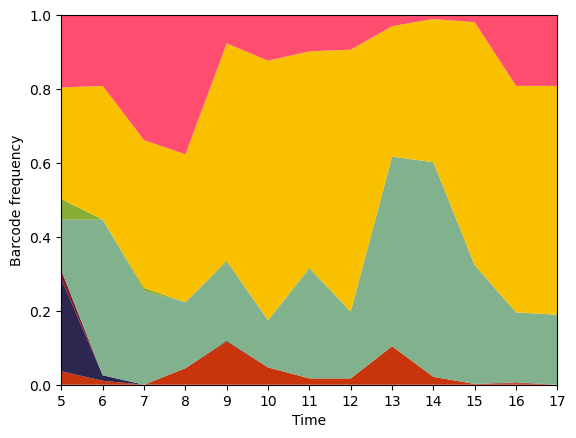

In [23]:
tm.visualize.plot(sample_df)